# **Team**: **Sagar Parajuli - CS26BTKMU11003**
#### Please also see github for any additional comments(README.md summary) or summary of all assignments as a whole
>https://github.com/SagarP-0/LO-Assignments/

# Minimum Vertex Cover and Maximum Matching in a Bipartite Graph
**Linear Optimisation, Assignment 4**

- Minimum vertex cover is written as an ILP and relaxed to an LP (primal)
- Maximum matching is the dual LP (fractional matching)
- Both LPs are solved with the geometric simplex method from Assignment 1
- LP solutions are converted to binary solutions with the threshold 0.5
- Results are checked against LP strong duality

## 1. Imports and configuration

- `CSV_PATH`: input edge list (two columns, no header)
- If the file is missing, a sample graph is created
- Tolerances are the same as in Assignment 1
- The simplex routine maximises `c^T x` subject to `A x <= b` with `rank(A) = n`
- A minimisation problem is solved as the maximisation of `-z`

In [ ]:
CSV_PATH = "graph_edges.csv"

In [ ]:
import csv
import itertools
import os
import re
from collections import deque
from dataclasses import dataclass, field

import numpy as np

np.set_printoptions(precision=4, suppress=True)

# tolerances
TOL_FEAS = 1e-8      # feasibility and tight constraints
TOL_RANK = 1e-9      # rank (relative to the largest singular value)
TOL_IMPROVE = 1e-9   # c.d must be larger than this to count as improving
TOL_DIR = 1e-9       # sign tests on direction vectors
TOL_STEP = 1e-12     # smallest step treated as non-zero
TOL_SAME = 1e-7      # two points or directions are the same

THRESHOLD = 0.5     # rounding threshold for LP values
TOL_CHECK = 1e-6    # tolerance for integrality and equality checks


def stop(message):
    """Print an error message and halt the notebook."""
    print("Error:", message)
    raise SystemExit


def verdict(ok):
    return "PASS" if ok else "FAIL"

## 2. CSV input and graph construction

Input rules
- Each row is one edge with exactly two non-empty fields
- No header row
- Fields are stripped of spaces
- Vertex ids are integers if every field is an integer, otherwise strings
- Blank lines are skipped

Validation
- Malformed row (not two non-empty fields): error
- Self-loop `(v, v)`: error, since the graph is then not bipartite
- Duplicate edge, including a reversed copy `(v, u)`: kept once, count reported

In [ ]:
if not os.path.exists(CSV_PATH):
    with open(CSV_PATH, "w") as f:
        f.write("A,B\nA,C\nB,D\nC,D\nD,E\nF,B\nA,G\nH,B\n")
    print(f"Created sample file {CSV_PATH}")

In [ ]:
def read_edges(path):
    """Read the edge list. Returns (vertices, edges, number_of_duplicates_removed)."""
    if not os.path.isfile(path):
        stop(f"File '{path}' not found.")
    rows = []
    with open(path, newline="") as f:
        for line_no, row in enumerate(csv.reader(f), start=1):
            if not row or all(t.strip() == "" for t in row):
                continue
            if len(row) != 2 or any(t.strip() == "" for t in row):
                stop(f"Row {line_no} is malformed: expected 2 non-empty fields, found {row}.")
            rows.append((row[0].strip(), row[1].strip(), line_no))
    if not rows:
        stop("The file contains no edges.")

    tokens = [t for u, v, _ in rows for t in (u, v)]
    if all(re.fullmatch(r"-?\d+", t) and str(int(t)) == t for t in tokens):
        rows = [(int(u), int(v), k) for u, v, k in rows]

    edges, seen, duplicates = [], set(), 0
    for u, v, line_no in rows:
        if u == v:
            stop(f"Row {line_no} is a self-loop ({u}, {v}); the graph is not bipartite.")
        key = frozenset((u, v))
        if key in seen:
            duplicates += 1
            continue
        seen.add(key)
        edges.append((u, v))
    vertices = sorted({t for e in edges for t in e})
    return vertices, edges, duplicates

In [ ]:
vertices, edges, n_dup = read_edges(CSV_PATH)
print(f"Vertices ({len(vertices)}): {', '.join(map(str, vertices))}")
print(f"Edges    ({len(edges)}): " + ", ".join(f"({u},{v})" for u, v in edges))
if n_dup:
    print(f"Duplicate edges removed: {n_dup}")

Vertices (8): A, B, C, D, E, F, G, H
Edges    (8): (A,B), (A,C), (B,D), (C,D), (D,E), (F,B), (A,G), (H,B)


## 3. Bipartition detection (BFS)

- Colour each connected component with two colours using BFS
- A start vertex gets colour 0, its neighbours colour 1, and so on
- If an edge joins two vertices of the same colour, the graph is not bipartite
- Colour 0 gives `U`, colour 1 gives `V`

In [ ]:
def bipartition(vertices, edges):
    """Two-colour the graph by BFS. Returns (U, V), or stops if the graph is not bipartite."""
    adj = {v: [] for v in vertices}
    for u, v in edges:
        adj[u].append(v)
        adj[v].append(u)
    colour = {}
    for start in vertices:
        if start in colour:
            continue
        colour[start] = 0
        queue = deque([start])
        while queue:
            u = queue.popleft()
            for w in adj[u]:
                if w not in colour:
                    colour[w] = 1 - colour[u]
                    queue.append(w)
                elif colour[w] == colour[u]:
                    stop(f"The graph is not bipartite: edge ({u}, {w}) joins two vertices "
                         f"of the same colour. Bipartite methods are not applied.")
    U = [v for v in vertices if colour[v] == 0]
    V = [v for v in vertices if colour[v] == 1]
    return U, V

In [ ]:
U, V = bipartition(vertices, edges)
print("The graph is bipartite.")
print(f"U = {{{', '.join(map(str, U))}}}")
print(f"V = {{{', '.join(map(str, V))}}}")

The graph is bipartite.
U = {A, D, F, H}
V = {B, C, E, G}


## 4. Primal ILP formulation

Variables: $x_i \in \{0,1\}$ for each vertex $i \in U \cup V$, with $x_i = 1$ if $i$ is in the cover.

$$\min z = \sum_{i \in U \cup V} x_i$$

$$\text{s.t.}\quad x_u + x_v \ge 1 \quad \forall (u,v) \in E, \qquad x_i \in \{0,1\}$$

- An edge is covered only if at least one endpoint is in the cover
- If both $x_u$ and $x_v$ were 0, the edge would have no endpoint in the cover
- So every edge needs $x_u + x_v \ge 1$

In [ ]:
def print_ilp(vertices, edges):
    print("Primal ILP (minimum vertex cover)")
    print("  Variables: x_i in {0,1} for every vertex i; x_i = 1 if i is in the cover\n")
    print("  minimise   z = " + " + ".join(f"x_{v}" for v in vertices))
    print("  subject to")
    for u, v in edges:
        print(f"    x_{u} + x_{v} ≥ 1        (edge {u}-{v})")
    print("    x_i ∈ {0,1}  for i = " + ", ".join(map(str, vertices)))

In [ ]:
print_ilp(vertices, edges)

Primal ILP (minimum vertex cover)
  Variables: x_i in {0,1} for every vertex i; x_i = 1 if i is in the cover

  minimise   z = x_A + x_B + x_C + x_D + x_E + x_F + x_G + x_H
  subject to
    x_A + x_B ≥ 1        (edge A-B)
    x_A + x_C ≥ 1        (edge A-C)
    x_B + x_D ≥ 1        (edge B-D)
    x_C + x_D ≥ 1        (edge C-D)
    x_D + x_E ≥ 1        (edge D-E)
    x_F + x_B ≥ 1        (edge F-B)
    x_A + x_G ≥ 1        (edge A-G)
    x_H + x_B ≥ 1        (edge H-B)
    x_i ∈ {0,1}  for i = A, B, C, D, E, F, G, H


## 5. Primal LP relaxation

Replace $x_i \in \{0,1\}$ by $0 \le x_i \le 1$.

- Variables: one per vertex, `n = |U| + |V|`
- Rows of `A x <= b` for the simplex routine:
  - edge `(u,v)`: `-x_u - x_v <= -1`
  - non-negativity: `-x_i <= 0`
  - upper bound: `x_i <= 1`
- Objective: `max -sum(x_i)`
- The `-x_i <= 0` rows give `rank(A) = n`

In [ ]:
def build_primal(vertices, edges):
    """Matrices (c, A, b) of the relaxed vertex cover LP in the form max c.x, A x <= b."""
    n = len(vertices)
    index = {v: i for i, v in enumerate(vertices)}
    rows, rhs = [], []
    for u, v in edges:
        row = np.zeros(n)
        row[index[u]] = row[index[v]] = -1
        rows.append(row)
        rhs.append(-1.0)
    rows += list(-np.eye(n))
    rhs += [0.0] * n
    rows += list(np.eye(n))
    rhs += [1.0] * n
    return -np.ones(n), np.array(rows), np.array(rhs)


def print_relaxed_primal(vertices, edges):
    print("Primal LP relaxation")
    print("  minimise   z = " + " + ".join(f"x_{v}" for v in vertices))
    print("  subject to")
    for u, v in edges:
        print(f"    x_{u} + x_{v} ≥ 1        (edge {u}-{v})")
    names = ", ".join(f"x_{v}" for v in vertices)
    print(f"    x_i ≥ 0   for {names}")
    print(f"    x_i ≤ 1   for {names}")

In [ ]:
print_relaxed_primal(vertices, edges)
c_p, A_p, b_p = build_primal(vertices, edges)
print(f"\nSimplex form: n = {A_p.shape[1]} variables, m = {A_p.shape[0]} constraints")

Primal LP relaxation
  minimise   z = x_A + x_B + x_C + x_D + x_E + x_F + x_G + x_H
  subject to
    x_A + x_B ≥ 1        (edge A-B)
    x_A + x_C ≥ 1        (edge A-C)
    x_B + x_D ≥ 1        (edge B-D)
    x_C + x_D ≥ 1        (edge C-D)
    x_D + x_E ≥ 1        (edge D-E)
    x_F + x_B ≥ 1        (edge F-B)
    x_A + x_G ≥ 1        (edge A-G)
    x_H + x_B ≥ 1        (edge H-B)
    x_i ≥ 0   for x_A, x_B, x_C, x_D, x_E, x_F, x_G, x_H
    x_i ≤ 1   for x_A, x_B, x_C, x_D, x_E, x_F, x_G, x_H

Simplex form: n = 8 variables, m = 24 constraints


## 6. Primal simplex solution

- The routines below are the geometric simplex from Assignment 1, unchanged
- Initial vertex: enumeration of `n` independent tight constraints
- Each iteration moves along an improving edge to the next vertex
- Enumeration cost grows like `C(m, n)`, so the method suits small graphs

In [ ]:
def numerical_rank(M, tol=TOL_RANK):
    M = np.atleast_2d(M)
    if M.size == 0:
        return 0
    s = np.linalg.svd(M, compute_uv=False)
    return int(np.sum(s > tol * max(1.0, s[0])))


def is_feasible(A, b, x, tol=TOL_FEAS):
    return bool(np.all(A @ x - b <= tol * (1 + np.abs(b))))


def tight_rows(A, b, x, tol=TOL_FEAS):
    return np.flatnonzero(np.abs(A @ x - b) <= tol * (1 + np.abs(b)))


def is_vertex(A, b, x):
    return is_feasible(A, b, x) and numerical_rank(A[tight_rows(A, b, x)]) == A.shape[1]


def fmt(x):
    v = np.asarray(x, float)
    v = np.where(np.abs(v) < 1e-9, 0.0, v)      # hide round-off such as -3e-16
    return "[" + ", ".join(f"{t:.4g}" for t in v) + "]"

In [ ]:
def find_initial_vertex(A, b, max_sets=2_000_000):
    """Return (vertex, status) with status 'found', 'infeasible' or 'undetermined'."""
    m, n = A.shape
    for count, rows in enumerate(itertools.combinations(range(m), n)):
        if count >= max_sets:
            return None, "undetermined"
        A_I = A[list(rows)]
        if numerical_rank(A_I) < n:
            continue
        x = np.linalg.solve(A_I, b[list(rows)])
        if is_feasible(A, b, x):
            return x, "found"
    return None, "infeasible"

In [ ]:
@dataclass
class Result:
    status: str          # optimal, unbounded, infeasible, undetermined, cycle, max_iterations, numerical_failure
    message: str = ""
    x: np.ndarray = None
    z: float = None
    path: list = field(default_factory=list)
    ray: np.ndarray = None
    start: np.ndarray = None


def edge_directions(A, tight):
    """Unit directions of the edges leaving the vertex with tight rows `tight`."""
    n = A.shape[1]
    A_T = A[tight]
    norms = np.linalg.norm(A_T, axis=1)
    found = []
    for J in itertools.combinations(range(len(tight)), n - 1):
        A_J = A_T[list(J)]
        if numerical_rank(A_J) != n - 1:
            continue
        # last right singular vector spans the null space of A_J
        d = np.array([1.0]) if n == 1 else np.linalg.svd(A_J)[2][-1]
        for sign in (1.0, -1.0):
            cand = sign * d
            if np.all(A_T @ cand <= TOL_DIR * norms):
                if not any(np.allclose(cand, e, atol=TOL_SAME) for e in found):
                    found.append(cand)
    return found


def ratio_test(A, b, x, d):
    """Largest step t with A(x + t d) <= b. Returns np.inf if no row blocks."""
    Ad = A @ d
    rows = np.flatnonzero(Ad > TOL_DIR * np.linalg.norm(A, axis=1))
    if rows.size == 0:
        return np.inf
    slack = np.maximum(b - A @ x, 0.0)
    return float(np.min(slack[rows] / Ad[rows]))


def geometric_simplex(A, b, c, x0, max_iter=1000):
    """Maximise c.x over A x <= b, moving along improving edges from vertex x0."""
    n = A.shape[1]
    x = np.array(x0, float)
    start = x.copy()
    path, seen = [], set()
    scale = 1 + np.linalg.norm(c)

    def stop(status, msg, pt):
        return Result(status, msg, pt, float(c @ pt), path, None, start)

    if not is_vertex(A, b, x):
        return stop("numerical_failure", "Starting point is not a vertex.", x)

    for it in range(max_iter + 1):
        z = float(c @ x)
        tight = tight_rows(A, b, x)
        path.append({"iter": it, "x": x.copy(), "z": z, "tight": tight.tolist()})
        seen.add(tuple(np.round(x, 6) + 0.0))

        # improving edges at this vertex
        moves = []
        for d in edge_directions(A, tight):
            if c @ d > TOL_IMPROVE * scale:
                t = ratio_test(A, b, x, d)
                if np.isinf(t):
                    r = stop("unbounded", "Improving ray with no blocking constraint.", x)
                    r.ray = d
                    return r
                moves.append((c @ d, t, d))

        if not moves:
            return Result("optimal", "", x.copy(), z, path, None, start)

        rate, t, d = max(moves, key=lambda m: m[0])
        if t <= TOL_STEP:
            return stop("numerical_failure", "Zero-length step.", x)

        # move to the next vertex and clean it up with the tight system
        x_new = x + t * d
        tight_new = tight_rows(A, b, x_new)
        if numerical_rank(A[tight_new]) != n:
            return stop("numerical_failure", "New point is not a vertex.", x_new)
        x_new = np.linalg.lstsq(A[tight_new], b[tight_new], rcond=None)[0]
        z_new = float(c @ x_new)
        if not is_feasible(A, b, x_new):
            return stop("numerical_failure", "New vertex is infeasible.", x_new)
        if abs(z_new - (z + t * rate)) > 1e-6 * (1 + abs(z_new)):
            return stop("numerical_failure", "Objective change does not match t * (c.d).", x_new)
        if tuple(np.round(x_new, 6) + 0.0) in seen:
            return stop("cycle", "Vertex repeated.", x_new)
        x = x_new

    return stop("max_iterations", f"Reached {max_iter} iterations.", x)


def solve_lp(c, A, b, x0=None, max_iter=1000):
    """Find a starting vertex (unless given) and run the geometric simplex."""
    c, A, b = (np.asarray(v, float) for v in (c, A, b))
    if x0 is None:
        x0, status = find_initial_vertex(A, b)
        if status == "infeasible":
            return Result("infeasible")
        if status == "undetermined":
            return Result("undetermined", "Search limit reached before a vertex was found.")
    return geometric_simplex(A, b, c, np.asarray(x0, float), max_iter)

`run_simplex` calls the routines above and prints the visited vertices

- `sign = -1` for a minimisation problem (the solver maximises `-z`)
- The printed objective is the original objective `z`
- The run stops with a message if the solver does not return `optimal`

In [ ]:
def run_simplex(c, A, b, names, sign):
    """Solve max c.x s.t. A x <= b and print the vertices visited."""
    if numerical_rank(A) != A.shape[1]:
        stop("rank(A) < n, so the simplex routine cannot be applied.")
    res = solve_lp(c, A, b)
    if res.status not in ("optimal",):
        print(f"Solver status: {res.status}. {res.message}")
        stop("The simplex run did not reach an optimal vertex. No substitute method is used.")

    print("Variable order: " + ", ".join(names))
    print(f"Initial vertex: {fmt(res.start)}\n")
    width = max(len(fmt(p["x"])) for p in res.path) + 3
    print(f"  {'iter':<6}{'vertex':<{width}}{'objective z'}")
    for p in res.path:
        print(f"  {p['iter']:<6}{fmt(p['x']):<{width}}{sign * p['z']:.6g}")
    print(f"\nOptimal vertex   : {fmt(res.x)}")
    print(f"Optimal objective: {sign * res.z:.6g}")
    print(f"Solver status    : {res.status}")
    return res

In [ ]:
x_names = [f"x_{v}" for v in vertices]
primal_res = run_simplex(c_p, A_p, b_p, x_names, sign=-1)
x_lp = primal_res.x
primal_opt = -primal_res.z

Variable order: x_A, x_B, x_C, x_D, x_E, x_F, x_G, x_H
Initial vertex: [0, 1, 1, 0, 1, 0, 1, 0]

  iter  vertex                     objective z
  0     [0, 1, 1, 0, 1, 0, 1, 0]   4
  1     [1, 1, 0, 1, 0, 0, 0, 0]   3

Optimal vertex   : [1, 1, 0, 1, 0, 0, 0, 0]
Optimal objective: 3
Solver status    : optimal


## 7. LP-to-ILP conversion

Direct thresholding of the optimal LP solution

$$x_i^{ILP} = \begin{cases} 1 & x_i^{LP} \ge 0.5 \\ 0 & x_i^{LP} < 0.5 \end{cases}$$

- For a bipartite graph the vertex cover LP has integral extreme points
- So the optimal vertex found by simplex should already be 0/1
- Thresholding then leaves the solution unchanged

In [ ]:
def threshold_table(names, values):
    """Apply the 0.5 rule to every value and print the decisions. Returns the binary list."""
    print(f"Threshold: {THRESHOLD}\n")
    print(f"  {'variable':<14}{'LP value':<12}{'decision':<18}{'binary'}")
    bits = []
    for name, val in zip(names, values):
        val = 0.0 if abs(val) < 1e-9 else float(val)
        bit = 1 if val >= THRESHOLD else 0
        rule = f"{val:.4f} ≥ 0.5" if bit else f"{val:.4f} < 0.5"
        print(f"  {name:<14}{val:<12.4f}{rule:<18}{bit}")
        bits.append(bit)
    return bits

In [ ]:
print("LP solution (primal)")
for name, val in zip(x_names, x_lp):
    print(f"  {name} = {0.0 if abs(val) < 1e-9 else val:.4f}")
print(f"  LP objective = {primal_opt:.6g}\n")

print("Conversion to ILP solution")
x_bits = threshold_table(x_names, x_lp)
cover = [v for v, bit in zip(vertices, x_bits) if bit == 1]
cover_size = sum(x_bits)
print(f"\nILP solution (binary): {x_bits}")
print(f"Selected vertices    : {{{', '.join(map(str, cover))}}}")
print(f"ILP objective value  : {cover_size}")

LP solution (primal)
  x_A = 1.0000
  x_B = 1.0000
  x_C = 0.0000
  x_D = 1.0000
  x_E = 0.0000
  x_F = 0.0000
  x_G = 0.0000
  x_H = 0.0000
  LP objective = 3

Conversion to ILP solution
Threshold: 0.5

  variable      LP value    decision          binary
  x_A           1.0000      1.0000 ≥ 0.5      1
  x_B           1.0000      1.0000 ≥ 0.5      1
  x_C           0.0000      0.0000 < 0.5      0
  x_D           1.0000      1.0000 ≥ 0.5      1
  x_E           0.0000      0.0000 < 0.5      0
  x_F           0.0000      0.0000 < 0.5      0
  x_G           0.0000      0.0000 < 0.5      0
  x_H           0.0000      0.0000 < 0.5      0

ILP solution (binary): [1, 1, 0, 1, 0, 0, 0, 0]
Selected vertices    : {A, B, D}
ILP objective value  : 3


### Verification of the vertex cover

In [ ]:
checks = [
    ("LP solution is integral",
     bool(np.all(np.abs(x_lp - np.round(x_lp)) <= TOL_CHECK))),
    ("Every edge has an endpoint in the cover",
     all(u in cover or v in cover for u, v in edges)),
    ("All variables are binary",
     all(bit in (0, 1) for bit in x_bits)),
    ("Objective value equals number of selected vertices",
     cover_size == len(cover)),
    ("ILP objective equals LP optimum",
     abs(cover_size - primal_opt) <= TOL_CHECK),
]
for text, ok in checks:
    print(f"  {text:<55}{verdict(ok)}")
cover_ok = all(ok for _, ok in checks)

  LP solution is integral                                PASS
  Every edge has an endpoint in the cover                PASS
  All variables are binary                               PASS
  Objective value equals number of selected vertices     PASS
  ILP objective equals LP optimum                        PASS


## 8. Dual formulation

Write the relaxed primal as $\min\ \mathbf{1}^T x$ subject to $Mx \ge \mathbf{1},\ x \ge 0$,
where $M$ is the edge-vertex incidence matrix (row $e=(u,v)$ has ones in columns $u$ and $v$).

**Correspondence**

| Primal | Dual |
|---|---|
| minimise $\sum_v x_v$ | maximise $\sum_e y_e$ |
| edge constraint $x_u + x_v \ge 1$ | variable $y_e \ge 0$ |
| variable $x_v \ge 0$ | vertex constraint $\sum_{e \ni v} y_e \le 1$ |
| right-hand side 1 of edge $e$ | objective coefficient 1 of $y_e$ |
| objective coefficient 1 of $x_v$ | right-hand side 1 of vertex $v$ |

**Why the dual constraints look like this**
- Take $y \ge 0$ with $\sum_{e \ni v} y_e \le 1$ for every vertex $v$
- For any feasible $x \ge 0$:

$$\sum_v x_v \;\ge\; \sum_v x_v \sum_{e \ni v} y_e \;=\; \sum_{e=(u,v)} y_e\,(x_u + x_v) \;\ge\; \sum_e y_e$$

- The first step uses $x_v \ge 0$ and $\sum_{e \ni v} y_e \le 1$
- The last step uses $y_e \ge 0$ and $x_u + x_v \ge 1$
- So every dual feasible value is a lower bound on the primal, and the best bound is the dual LP

**Upper bounds $x_v \le 1$**
- They are redundant: lowering any $x_v > 1$ to 1 keeps every edge constraint satisfied and does not increase $z$
- Their multipliers $s_v \ge 0$ appear as $\sum_{e \ni v} y_e - s_v \le 1$ with objective $\sum_e y_e - \sum_v s_v$
- The optimum uses $s_v = 0$, which gives the dual below

**Dual LP (fractional matching)**

$$\max w = \sum_{e \in E} y_e \quad \text{s.t.} \quad \sum_{e \ni v} y_e \le 1 \;\; \forall v \in U \cup V, \qquad y_e \ge 0 \;\; \forall e \in E$$

In [ ]:
def build_dual(vertices, edges):
    """Matrices (c, A, b) of the fractional matching LP in the form max c.x, A y <= b."""
    m_e = len(edges)
    rows, rhs = [], []
    for v in vertices:
        rows.append(np.array([1.0 if v in e else 0.0 for e in edges]))
        rhs.append(1.0)
    rows += list(-np.eye(m_e))
    rhs += [0.0] * m_e
    return np.ones(m_e), np.array(rows), np.array(rhs)


def print_dual(vertices, edges):
    y = {e: f"y({e[0]},{e[1]})" for e in edges}
    print("Dual LP (fractional matching)")
    print("  Variables: one y_e ≥ 0 for every edge e, from the edge constraints of the primal\n")
    print("  maximise   w = " + " + ".join(y.values()))
    print("  subject to")
    lines = [(" + ".join(y[e] for e in edges if v in e) + " ≤ 1", f"(vertex {v}, from x_{v})")
             for v in vertices]
    width = max(len(l) for l, _ in lines) + 4
    for left, right in lines:
        print(f"    {left:<{width}}{right}")
    print("    y_e ≥ 0   for " + ", ".join(y.values()))

In [ ]:
print_dual(vertices, edges)
c_d, A_d, b_d = build_dual(vertices, edges)
print(f"\nSimplex form: n = {A_d.shape[1]} variables, m = {A_d.shape[0]} constraints, "
      f"rank(A) = {numerical_rank(A_d)}")

Dual LP (fractional matching)
  Variables: one y_e ≥ 0 for every edge e, from the edge constraints of the primal

  maximise   w = y(A,B) + y(A,C) + y(B,D) + y(C,D) + y(D,E) + y(F,B) + y(A,G) + y(H,B)
  subject to
    y(A,B) + y(A,C) + y(A,G) ≤ 1             (vertex A, from x_A)
    y(A,B) + y(B,D) + y(F,B) + y(H,B) ≤ 1    (vertex B, from x_B)
    y(A,C) + y(C,D) ≤ 1                      (vertex C, from x_C)
    y(B,D) + y(C,D) + y(D,E) ≤ 1             (vertex D, from x_D)
    y(D,E) ≤ 1                               (vertex E, from x_E)
    y(F,B) ≤ 1                               (vertex F, from x_F)
    y(A,G) ≤ 1                               (vertex G, from x_G)
    y(H,B) ≤ 1                               (vertex H, from x_H)
    y_e ≥ 0   for y(A,B), y(A,C), y(B,D), y(C,D), y(D,E), y(F,B), y(A,G), y(H,B)

Simplex form: n = 8 variables, m = 16 constraints, rank(A) = 8


## 9. Dual simplex solution

- Same routines and output format as the primal run
- The dual is a maximisation, so `sign = +1`

In [ ]:
y_names = [f"y({u},{v})" for u, v in edges]
dual_res = run_simplex(c_d, A_d, b_d, y_names, sign=+1)
y_lp = dual_res.x
dual_opt = dual_res.z

Variable order: y(A,B), y(A,C), y(B,D), y(C,D), y(D,E), y(F,B), y(A,G), y(H,B)
Initial vertex: [0, 1, 0, 0, 1, 1, 0, 0]

  iter  vertex                     objective z
  0     [0, 1, 0, 0, 1, 1, 0, 0]   3

Optimal vertex   : [0, 1, 0, 0, 1, 1, 0, 0]
Optimal objective: 3
Solver status    : optimal


## 10. Dual-to-matching conversion

Direct thresholding of the optimal fractional matching

$$y_e^{M} = \begin{cases} 1 & y_e^{LP} \ge 0.5 \\ 0 & y_e^{LP} < 0.5 \end{cases}$$

- The bipartite fractional matching LP has integral extreme points
- So the optimal vertex found by simplex should already be 0/1

In [ ]:
print("LP solution (dual)")
for name, val in zip(y_names, y_lp):
    print(f"  {name} = {0.0 if abs(val) < 1e-9 else val:.4f}")
print(f"  LP objective = {dual_opt:.6g}\n")

print("Conversion to matching")
y_bits = threshold_table(y_names, y_lp)
matching = [e for e, bit in zip(edges, y_bits) if bit == 1]
match_size = sum(y_bits)
print(f"\nBinary edge variables: {y_bits}")
print("Selected edges       : " + (", ".join(f"({u},{v})" for u, v in matching) or "none"))
print(f"Matching size        : {match_size}")

LP solution (dual)
  y(A,B) = 0.0000
  y(A,C) = 1.0000
  y(B,D) = 0.0000
  y(C,D) = 0.0000
  y(D,E) = 1.0000
  y(F,B) = 1.0000
  y(A,G) = 0.0000
  y(H,B) = 0.0000
  LP objective = 3

Conversion to matching
Threshold: 0.5

  variable      LP value    decision          binary
  y(A,B)        0.0000      0.0000 < 0.5      0
  y(A,C)        1.0000      1.0000 ≥ 0.5      1
  y(B,D)        0.0000      0.0000 < 0.5      0
  y(C,D)        0.0000      0.0000 < 0.5      0
  y(D,E)        1.0000      1.0000 ≥ 0.5      1
  y(F,B)        1.0000      1.0000 ≥ 0.5      1
  y(A,G)        0.0000      0.0000 < 0.5      0
  y(H,B)        0.0000      0.0000 < 0.5      0

Binary edge variables: [0, 1, 0, 0, 1, 1, 0, 0]
Selected edges       : (A,C), (D,E), (F,B)
Matching size        : 3


### Verification of the matching

In [ ]:
endpoints = [t for e in matching for t in e]
edge_set = {frozenset(e) for e in edges}
checks = [
    ("LP solution is integral",
     bool(np.all(np.abs(y_lp - np.round(y_lp)) <= TOL_CHECK))),
    ("Every selected edge belongs to the graph",
     all(frozenset(e) in edge_set for e in matching)),
    ("No two selected edges share an endpoint",
     len(endpoints) == len(set(endpoints))),
    ("All variables are binary",
     all(bit in (0, 1) for bit in y_bits)),
    ("Matching size equals sum of edge variables",
     match_size == len(matching)),
    ("Matching size equals LP optimum",
     abs(match_size - dual_opt) <= TOL_CHECK),
]
for text, ok in checks:
    print(f"  {text:<55}{verdict(ok)}")
matching_ok = all(ok for _, ok in checks)

  LP solution is integral                                PASS
  Every selected edge belongs to the graph               PASS
  No two selected edges share an endpoint                PASS
  All variables are binary                               PASS
  Matching size equals sum of edge variables             PASS
  Matching size equals LP optimum                        PASS


## 11. Final verification

- **Strong duality:** primal LP optimum = dual LP optimum
- **Integrality:** the incidence matrix of a bipartite graph is totally unimodular, so both LPs have integral extreme points
- Hence the LP optima equal the ILP vertex cover size and the maximum matching size
- **König's theorem:** minimum vertex cover size = maximum matching size

In [ ]:
print(f"{'Quantity':<34}{'Value'}")
print("-" * 44)
print(f"{'Primal LP optimum':<34}{primal_opt:.6g}")
print(f"{'Dual LP optimum':<34}{dual_opt:.6g}")
print(f"{'ILP minimum vertex cover size':<34}{cover_size}")
print(f"{'Maximum matching size':<34}{match_size}")

duality_ok = abs(primal_opt - dual_opt) <= TOL_CHECK
konig_ok = cover_size == match_size
print()
print(f"  Primal LP optimum = Dual LP optimum                 {verdict(duality_ok)}")
print(f"  Minimum vertex cover size = Maximum matching size   {verdict(konig_ok)}")
print(f"  Vertex cover feasibility checks                     {verdict(cover_ok)}")
print(f"  Matching feasibility checks                         {verdict(matching_ok)}")

if not (duality_ok and konig_ok and cover_ok and matching_ok):
    print("\nDiscrepancy found. Solutions:")
    print(f"  primal LP vertex: {fmt(x_lp)}")
    print(f"  dual LP vertex  : {fmt(y_lp)}")
    print(f"  cover: {cover}, matching: {matching}")
else:
    print("\nAll verification checks passed.")

Quantity                          Value
--------------------------------------------
Primal LP optimum                 3
Dual LP optimum                   3
ILP minimum vertex cover size     3
Maximum matching size             3

  Primal LP optimum = Dual LP optimum                 PASS
  Minimum vertex cover size = Maximum matching size   PASS
  Vertex cover feasibility checks                     PASS
  Matching feasibility checks                         PASS

All verification checks passed.


## 12. Graph plot

- Left: the input graph, with `U` on the top row and `V` on the bottom row
- Right: the solution
  - filled vertices form the minimum vertex cover
  - thick edges form the maximum matching

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def plot_solution(U, V, edges, cover, matching):
    """Draw the bipartite graph before and after solving."""
    blue, light, grey, ink = "#2a6fdb", "#9dbbf0", "#b8bec6", "#222222"
    pos = {}
    for part, y in ((U, 1.0), (V, 0.0)):
        for i, v in enumerate(part):
            pos[v] = (i - (len(part) - 1) / 2, y)
    half = (max(len(U), len(V)) - 1) / 2 + 0.8
    matched = {frozenset(e) for e in matching}

    fig, axes = plt.subplots(1, 2, figsize=(max(8, 2.6 * half), 3.4))
    for ax, solved in zip(axes, (False, True)):
        for u, v in edges:
            hit = solved and frozenset((u, v)) in matched
            covered = solved and (u in cover or v in cover)   # edge touched by a cover vertex
            color, lw = (blue, 3) if hit else (light, 2) if covered else (grey, 1.2)
            ax.plot(*zip(pos[u], pos[v]), color=color, lw=lw,
                    solid_capstyle="round", zorder=2 if hit else 1)
        for v, (x, y) in pos.items():
            filled = solved and v in cover
            ax.scatter(x, y, s=650, color=blue if filled else "white",
                       edgecolor=blue if filled else grey, linewidth=1.5, zorder=3)
            ax.text(x, y, str(v), ha="center", va="center", fontsize=11, zorder=4,
                    color="white" if filled else ink)
        ax.text(-half, 1, "U", ha="left", va="center", color=grey, fontsize=11)
        ax.text(-half, 0, "V", ha="left", va="center", color=grey, fontsize=11)
        ax.set_xlim(-half, half)
        ax.set_ylim(-0.4, 1.4)
        ax.axis("off")
    axes[0].set_title("Input graph", color=ink, fontsize=11)
    axes[1].set_title("Vertex cover and matching", color=ink, fontsize=11)
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=blue, markersize=9, label="vertex cover"),
                        Line2D([], [], color=light, lw=2, label="edge covered by cover"),
                        Line2D([], [], color=blue, lw=3, label="matching edge")],
               loc="lower center", ncol=3, frameon=False, fontsize=10)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

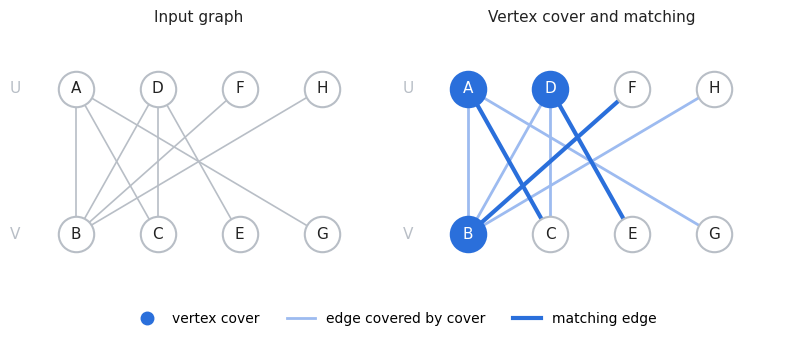

In [ ]:
plot_solution(U, V, edges, cover, matching)